In [1]:
# !pip install -r requirements.txt

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

# Prepare data

In [3]:
image_paths = glob.glob('./data/*.jpg')
json_paths = [pth.replace('jpg', 'json') for pth in image_paths]
image_paths, json_paths

(['./data\\001_IT135673_1.jpg',
  './data\\003_IT158279_1.jpg',
  './data\\004_IT158286_1.jpg',
  './data\\006_IT158412_1.jpg',
  './data\\008_IT158764_1.jpg',
  './data\\009_IT221893_1.jpg',
  './data\\010_IT223741_1.jpg',
  './data\\011_IT223788_1.jpg',
  './data\\012_IT225004_1.jpg'],
 ['./data\\001_IT135673_1.json',
  './data\\003_IT158279_1.json',
  './data\\004_IT158286_1.json',
  './data\\006_IT158412_1.json',
  './data\\008_IT158764_1.json',
  './data\\009_IT221893_1.json',
  './data\\010_IT223741_1.json',
  './data\\011_IT223788_1.json',
  './data\\012_IT225004_1.json'])

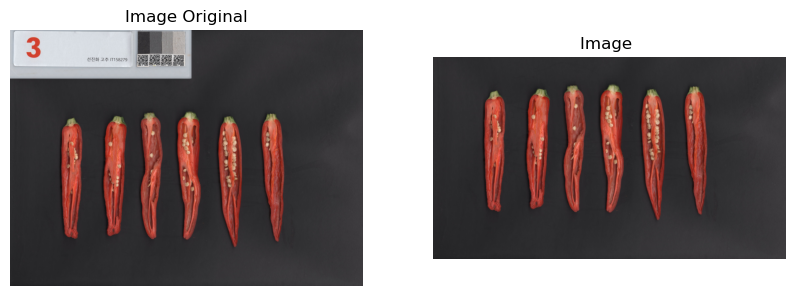

In [4]:
image = cv2.imread(image_paths[1])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_crop = image_RGB[540:, :, :]

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(image_RGB)
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_crop)
plt.title("Image ")
plt.axis("off")

plt.show()

# Get Bbox

### Detect bbox by threshold

In [5]:
# from segment import SegmentModel
from src.detect import DetectModel

model_detect = DetectModel(model_name='none')
# model_detect.predict(image_paths[0])

Use threshold for detect each chili fruit


In [6]:
path = image_paths[2]
masks = model_detect.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"runs/detect/predict/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

### Detect chili by model YOLO

- chưa load được model gọn nhẹ

# Segment for each chili

In [7]:
from src.segment import SegmentModel

model_seg = SegmentModel(weight_path='./pretrain/yolov8_segment_v1.pt', model_name='yolo')

In [8]:
import glob

img_paths = glob.glob('./runs/detect/predict/*.jpg')
imgs = [cv2.imread(path) for path in img_paths]
RGB_imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imgs]

results = model_seg.predict(RGB_imgs[0])

r = results['raw_results'][0]  # first image result


0: 640x224 12 seeds, 1 placenta, 1 endocarp, 457.7ms
Speed: 12.4ms preprocess, 457.7ms inference, 96.6ms postprocess per image at shape (1, 3, 640, 224)


In [9]:
[i['class_name'] for i in results['polygons']]

['placenta',
 'endocrap',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed']

In [10]:
names = r.names
masks = r.masks.data
polygons = r.masks.xy
xyxy = r.boxes.xyxy      # (N,4)
cls  = r.boxes.cls
conf = r.boxes.conf

In [11]:
masks.shape

torch.Size([14, 1726, 551])

# Test pipeline


0: 640x224 15 seeds, 2 placentas, 1 endocarp, 318.3ms
Speed: 1.3ms preprocess, 318.3ms inference, 35.1ms postprocess per image at shape (1, 3, 640, 224)
0 [582, 1293, 208, 857]

0: 640x192 10 seeds, 1 placenta, 1 endocarp, 265.8ms
Speed: 0.9ms preprocess, 265.8ms inference, 18.8ms postprocess per image at shape (1, 3, 640, 192)
1 [1063, 1242, 190, 869]

0: 640x256 8 seeds, 1 placenta, 1 endocarp, 327.8ms
Speed: 1.4ms preprocess, 327.8ms inference, 13.6ms postprocess per image at shape (1, 3, 640, 256)
2 [1607, 1297, 235, 816]

0: 640x224 7 seeds, 1 placenta, 1 endocarp, 402.4ms
Speed: 1.3ms preprocess, 402.4ms inference, 14.0ms postprocess per image at shape (1, 3, 640, 224)
3 [2076, 1322, 206, 799]

0: 640x256 12 seeds, 1 placenta, 1 endocarp, 320.0ms
Speed: 1.1ms preprocess, 320.0ms inference, 30.0ms postprocess per image at shape (1, 3, 640, 256)
4 [2577, 1266, 212, 778]

0: 640x224 3 seeds, 1 placenta, 1 endocarp, 520.9ms
Speed: 3.8ms preprocess, 520.9ms inference, 8.7ms postproce

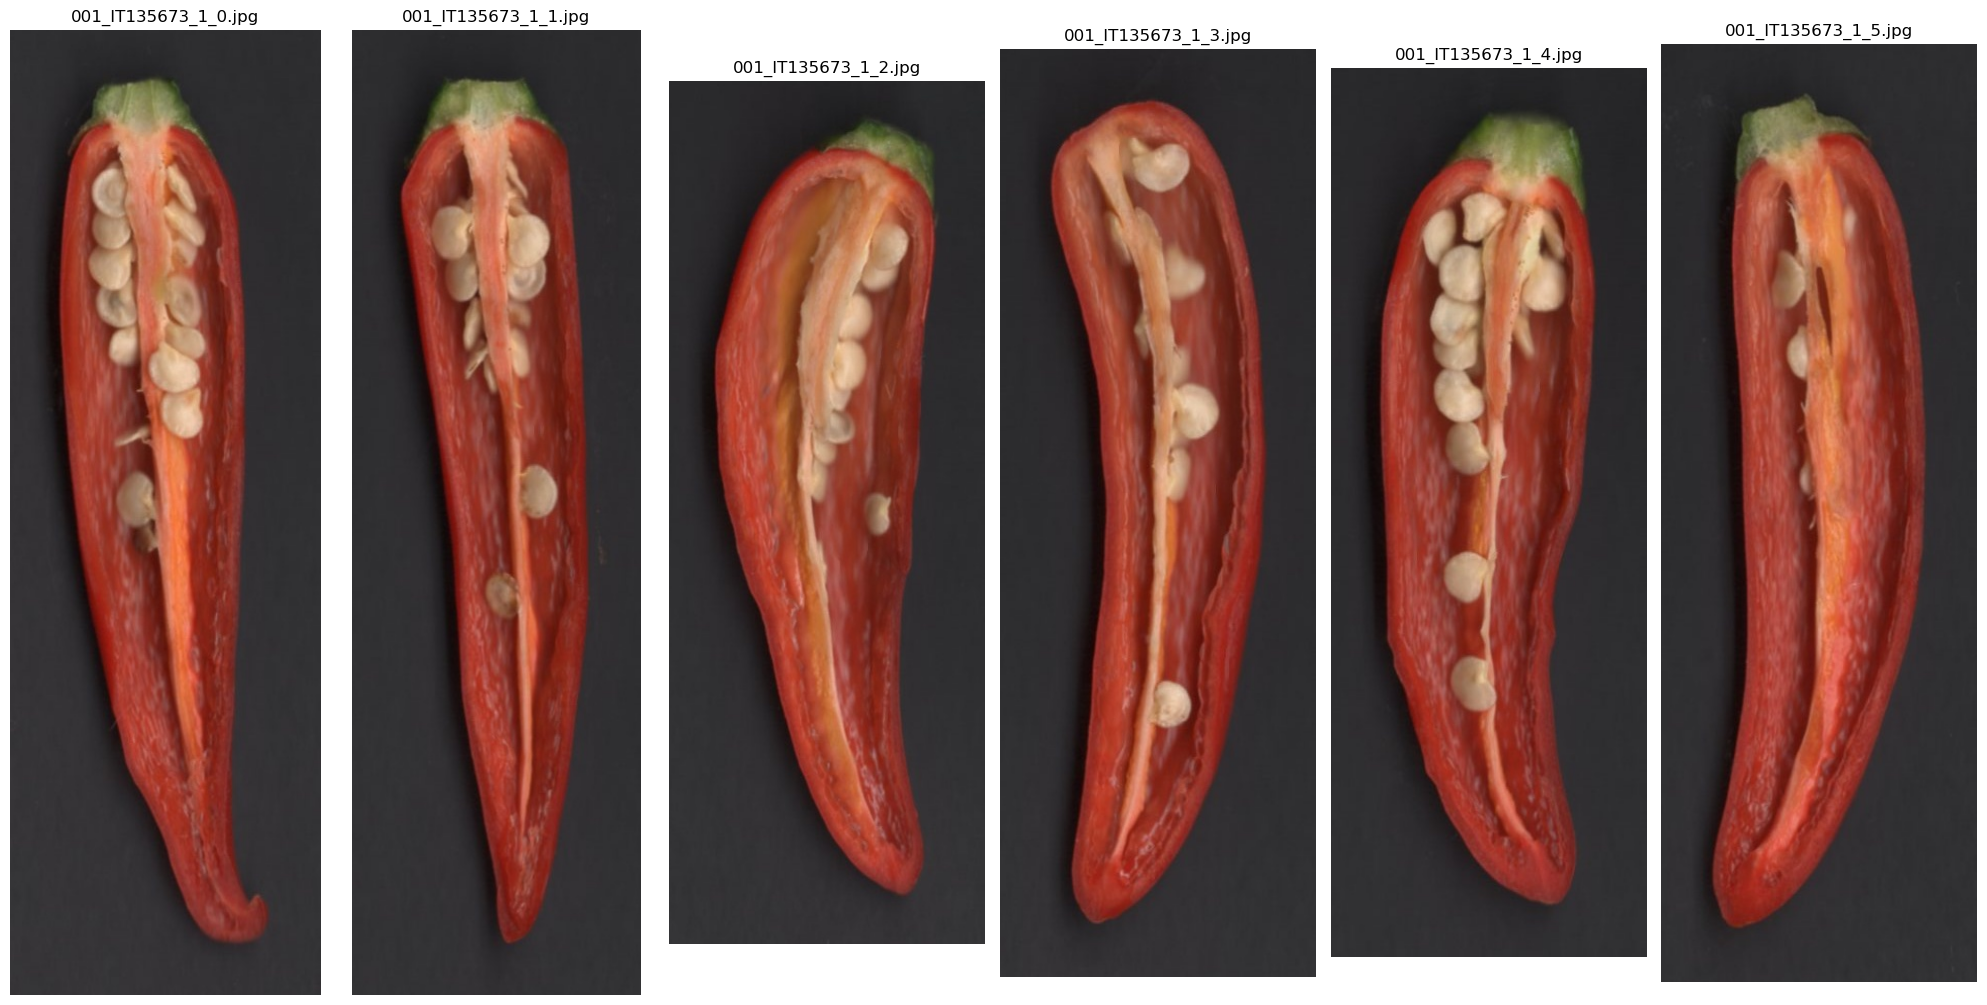

In [12]:
from src.object import Fruits

fruits = Fruits(image_paths[0], model_detect, model_seg)
fruits.show()
# fruits.items[0].rseg

In [29]:
fruits.items[0].rseg['raw_results'][0].masks.xy[0]
fruits.items[0].polygons[0].keys()

dict_keys(['class_id', 'class_name', 'points', 'points_normalized'])

# Accuracy

# App demo